# Process a monocular *elevation* session

Same as `process-monocular-session.ipynb`, but for a session recorded with
`teensyStimulusMonocular`'s `opts.elevations` set (repeats the azimuth sweep at
several fixed screen heights instead of just the center). See
`GogglesDevice.has_elevation` / `MonocularDevice._get_repeats(eye=, elevation=)`.

Builds the `MonocularDevice`, then:
1. Runs the "regular" analysis restricted to the 120px (center) elevation --
   saved as `{session_name}_dataframe.pkl`, the same file/schema
   `monocular-disparity-distance-comparison.ipynb` already reads via
   `CrossExperimentAnalysis.from_devices(R, M, D)`.
2. Runs `SessionAnalyzer.analyze_by_elevation` to get every swept elevation,
   saved separately as `{session_name}_by_elevation_dataframe.pkl`, and plots
   response strength vs. elevation per eye.

Run this in its own kernel with **only** `disparity-analysis` on `sys.path`.

In [1]:
import sys, os
import pandas as pd

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.MonocularDevice import MonocularDevice
from src.analysis.CellAnalysis import SessionAnalyzer

%load_ext autoreload
%autoreload 2

In [4]:
mouse, date, experiment = "SAM045", "260827", "monocular"   # <-- fill in your elevation session
M = MonocularDevice(mouse_name=mouse, record_date=date, experiment_name=experiment)
print("session:", M.session_name, "| eyes:", M.present_eyes, "| cells:", len(M.suite2p_id))
print("has_elevation:", M.has_elevation,
      "| elevations (px):", M.elevations.tolist() if M.has_elevation else None)

Directory results already exists
session: 260827_SAM045_monocular | eyes: ['right', 'left'] | cells: 1209
has_elevation: True | elevations (px): [60.0, 90.0, 120.0, 150.0, 180.0]


## 1. Regular analysis (120px / center elevation)

Same pkl filename/schema as the non-elevation notebook, so downstream
cross-experiment code keeps reading it unchanged. Falls back to no elevation
filter automatically if this session turns out not to have a sweep.

In [5]:
elev_kwargs = {'elevation': 120.0} if M.has_elevation else {}
if M.has_elevation:
    print(f"Session swept elevations {M.elevations.tolist()} px -- using 120px as the 'regular' condition.")

pkl_path = os.path.join(M.data_dir, f"{M.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = SessionAnalyzer(M).analyze_session_stats(n_iterations=200, **elev_kwargs)
    SessionAnalyzer(M).save_dataframe(stats_df)   # -> pkl_path
stats_df.head()

Session swept elevations [60.0, 90.0, 120.0, 150.0, 180.0] px -- using 120px as the 'regular' condition.
Saved DataFrame to: D:/data-distance-coding-project/processed-data\260827_SAM045_monocular\260827_SAM045_monocular_dataframe.pkl


,cell,session_name,right_reliable,right_mean_corr,right_rf,right_rf_value,right_px,left_reliable,left_mean_corr,left_rf,left_rf_value,left_px,ODI,elevation
0,0,260827_SAM045_monocular,False,0.004820,11,0.328252,22.372881,False,0.216628,39,0.813516,-40.677966,-0.425011,120.0
1,1,260827_SAM045_monocular,False,0.530816,59,0.337144,120.000000,False,-0.274732,39,0.307757,-40.677966,0.045567,120.0
2,2,260827_SAM045_monocular,False,0.423038,23,-0.003854,46.779661,False,0.147310,37,0.559459,-44.745763,-0.986315,120.0
3,3,260827_SAM045_monocular,False,-0.037311,8,0.301352,16.271186,False,0.423669,25,0.225253,-69.152542,0.144508,120.0
4,4,260827_SAM045_monocular,False,-0.180783,11,0.082802,22.372881,False,0.017856,2,0.311112,-115.932203,-0.579595,120.0


## 2. Explore how responses change across elevation

One block of per-cell rows per swept elevation, concatenated into a single
long-format DataFrame (tagged by an `elevation` column). Only meaningful if
`M.has_elevation` is True.

In [6]:
elev_pkl_path = os.path.join(M.data_dir, f"{M.session_name}_by_elevation_dataframe.pkl")
if os.path.exists(elev_pkl_path):
    by_elev_df = pd.read_pickle(elev_pkl_path)
    print(f"Loaded cached per-elevation stats: {elev_pkl_path}")
else:
    by_elev_df = SessionAnalyzer(M).analyze_by_elevation(n_iterations=200)
    by_elev_df.to_pickle(elev_pkl_path)
    print(f"Saved per-elevation stats: {elev_pkl_path}")
by_elev_df.head()

=== Elevation 60 px ===                    
=== Elevation 90 px ===                    
=== Elevation 120 px ===                    
=== Elevation 150 px ===                    
=== Elevation 180 px ===                    
Saved per-elevation stats: D:/data-distance-coding-project/processed-data\260827_SAM045_monocular\260827_SAM045_monocular_by_elevation_dataframe.pkl


,cell,session_name,right_reliable,right_mean_corr,right_rf,right_rf_value,right_px,left_reliable,left_mean_corr,left_rf,left_rf_value,left_px,ODI,elevation
0,0,260827_SAM045_monocular,False,-0.124725,19,0.305654,38.644068,False,-0.026797,30,0.251881,-58.983051,0.096448,60.0
1,1,260827_SAM045_monocular,False,0.186594,13,0.303845,26.440678,False,0.455283,14,0.232192,-91.525424,0.133672,60.0
2,2,260827_SAM045_monocular,False,-0.050024,18,0.016323,36.610169,False,0.252359,49,0.463316,-20.338983,-0.931935,60.0
3,3,260827_SAM045_monocular,False,0.027650,56,0.192835,113.898305,False,0.314617,25,0.263702,-69.152542,-0.155228,60.0
4,4,260827_SAM045_monocular,False,-0.498676,26,0.054313,52.881356,False,-0.155015,22,0.354470,-75.254237,-0.734270,60.0


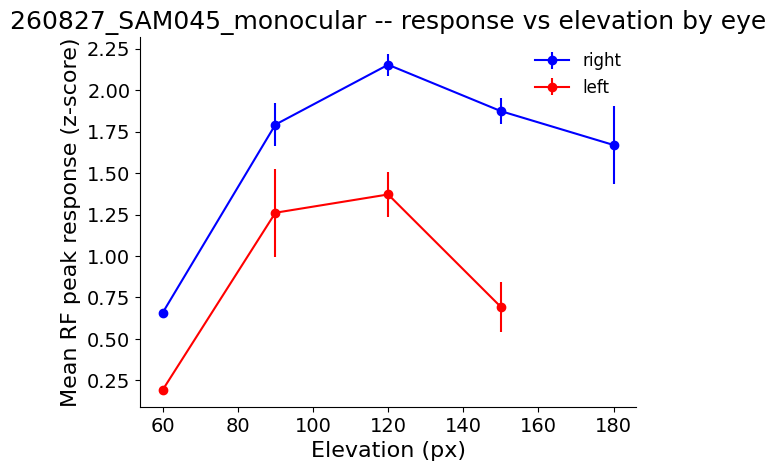

In [7]:
import matplotlib.pyplot as plt

EYE_COLOR = {'left': 'red', 'right': 'blue'}   # matches CellVisualizer.EYE_COLOR

# NOTE: this filters each elevation block by that block's OWN reliability, which drops
# a cell's off-preferred elevations rather than showing its full tuning shape (including
# the weak-but-real responses away from peak). If you want the full curve per reliably-
# driven cell instead, filter once by the 120px-condition's `reliable` column in stats_df
# and then plot that same cell subset's rf_value across all elevations in by_elev_df.
for eye in M.present_eyes:
    reliable = by_elev_df[by_elev_df[f'{eye}_reliable']]
    summary = reliable.groupby('elevation')[f'{eye}_rf_value'].agg(['mean', 'sem'])
    plt.errorbar(summary.index, summary['mean'], yerr=summary['sem'],
                 marker='o', color=EYE_COLOR[eye], label=eye)

plt.xlabel('Elevation (px)')
plt.ylabel('Mean RF peak response (z-score)')
plt.title(f'{M.session_name} -- response vs elevation by eye')
plt.legend(frameon=False)
plt.show()

In [22]:
def print_summary_by_elevation(by_elev_df, session_name=None, corr_threshold=None):
    """
    Same layout as SessionVisualizer.print_summary(), one block per elevation
    instead of one overall summary. Works directly off the long-format
    DataFrame from SessionAnalyzer.analyze_by_elevation() (one row per cell
    per elevation, tagged by an 'elevation' column).

    corr_threshold, if set, adds a mean_corr floor on top of each eye's
    'reliable' flag -- same semantics as SessionVisualizer's corr_threshold.
    """
    def pct(k, n):
        return f"{100 * k / n:5.1f}%" if n else "  n/a"

    session_name = session_name or by_elev_df['session_name'].iloc[0]
    line = "=" * 50

    for elev in sorted(by_elev_df['elevation'].unique()):
        df = by_elev_df[by_elev_df['elevation'] == elev]
        n = len(df)

        right_mask = df['right_reliable'].astype(bool)
        left_mask = df['left_reliable'].astype(bool)
        if corr_threshold is not None:
            right_mask &= df['right_mean_corr'] >= corr_threshold
            left_mask &= df['left_mean_corr'] >= corr_threshold

        right = set(df.loc[right_mask, 'cell'])
        left = set(df.loc[left_mask, 'cell'])
        both = right & left
        right_only, left_only = right - both, left - both
        either = right | left
        neither = set(df['cell']) - either

        print(line)
        print(f" Session: {session_name}  |  Elevation: {elev:.0f} px")
        print(f" Total cells: {n}")
        if corr_threshold is not None:
            print(f" mean_corr floor: {corr_threshold}")
        print("-" * 50)
        print(f" {'Right reliable':22s}: {len(right):4d}  ({pct(len(right), n)})")
        print(f" {'Left reliable':22s}: {len(left):4d}  ({pct(len(left), n)})")
        print(f" {'Both eyes reliable':22s}: {len(both):4d}  ({pct(len(both), n)})")
        print("-" * 50)
        print(f" {'Right-only':22s}: {len(right_only):4d}")
        print(f" {'Left-only':22s}: {len(left_only):4d}")
        print(f" {'Either eye':22s}: {len(either):4d}  ({pct(len(either), n)})")
        print(f" {'Neither':22s}: {len(neither):4d}  ({pct(len(neither), n)})")
    print(line)


# usage:
# print_summary_by_elevation(by_elev_df)
# or with the same corr_threshold floor you use elsewhere:
print_summary_by_elevation(by_elev_df, corr_threshold=0.75)

 Session: 260827_SAM045_monocular  |  Elevation: 60 px
 Total cells: 1209
 mean_corr floor: 0.75
--------------------------------------------------
 Right reliable        :    0  (  0.0%)
 Left reliable         :    0  (  0.0%)
 Both eyes reliable    :    0  (  0.0%)
--------------------------------------------------
 Right-only            :    0
 Left-only             :    0
 Either eye            :    0  (  0.0%)
 Neither               : 1209  (100.0%)
 Session: 260827_SAM045_monocular  |  Elevation: 90 px
 Total cells: 1209
 mean_corr floor: 0.75
--------------------------------------------------
 Right reliable        :   54  (  4.5%)
 Left reliable         :    3  (  0.2%)
 Both eyes reliable    :    0  (  0.0%)
--------------------------------------------------
 Right-only            :   54
 Left-only             :    3
 Either eye            :   57  (  4.7%)
 Neither               : 1152  ( 95.3%)
 Session: 260827_SAM045_monocular  |  Elevation: 120 px
 Total cells: 1209
 mean_c

 Session: 260827_SAM045_monocular
 Eyes shown: right, left
 Total cells: 1209
 mean_corr floor: 0.7
--------------------------------------------------
 Right reliable        :  442  ( 36.6%)
 Left reliable         :   17  (  1.4%)
 Both eyes reliable    :    8  (  0.7%)
--------------------------------------------------
 Right-only            :  434
 Left-only             :    9
 Either eye            :  451  ( 37.3%)
 Neither               :  758  ( 62.7%)
 Session: 260827_SAM045_monocular
 Eyes shown: right, left
 Total cells: 1209
 mean_corr floor: 0.7
--------------------------------------------------
 Right reliable        :  442  ( 36.6%)
 Left reliable         :   17  (  1.4%)
 Both eyes reliable    :    8  (  0.7%)
--------------------------------------------------
 Right-only            :  434
 Left-only             :    9
 Either eye            :  451  ( 37.3%)
 Neither               :  758  ( 62.7%)


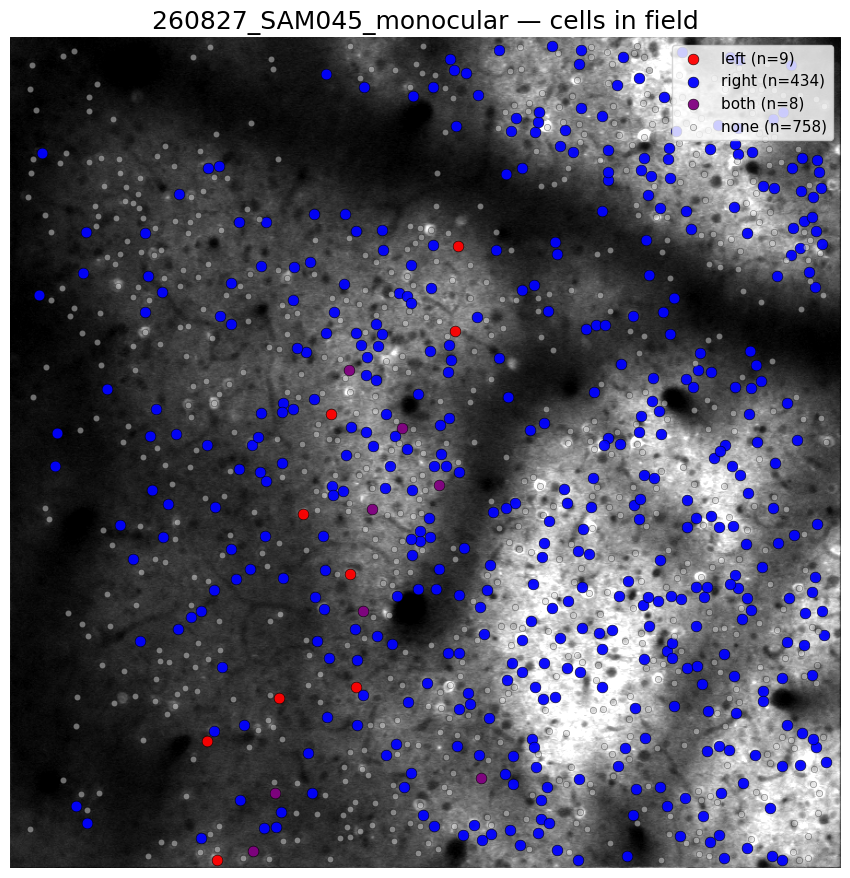

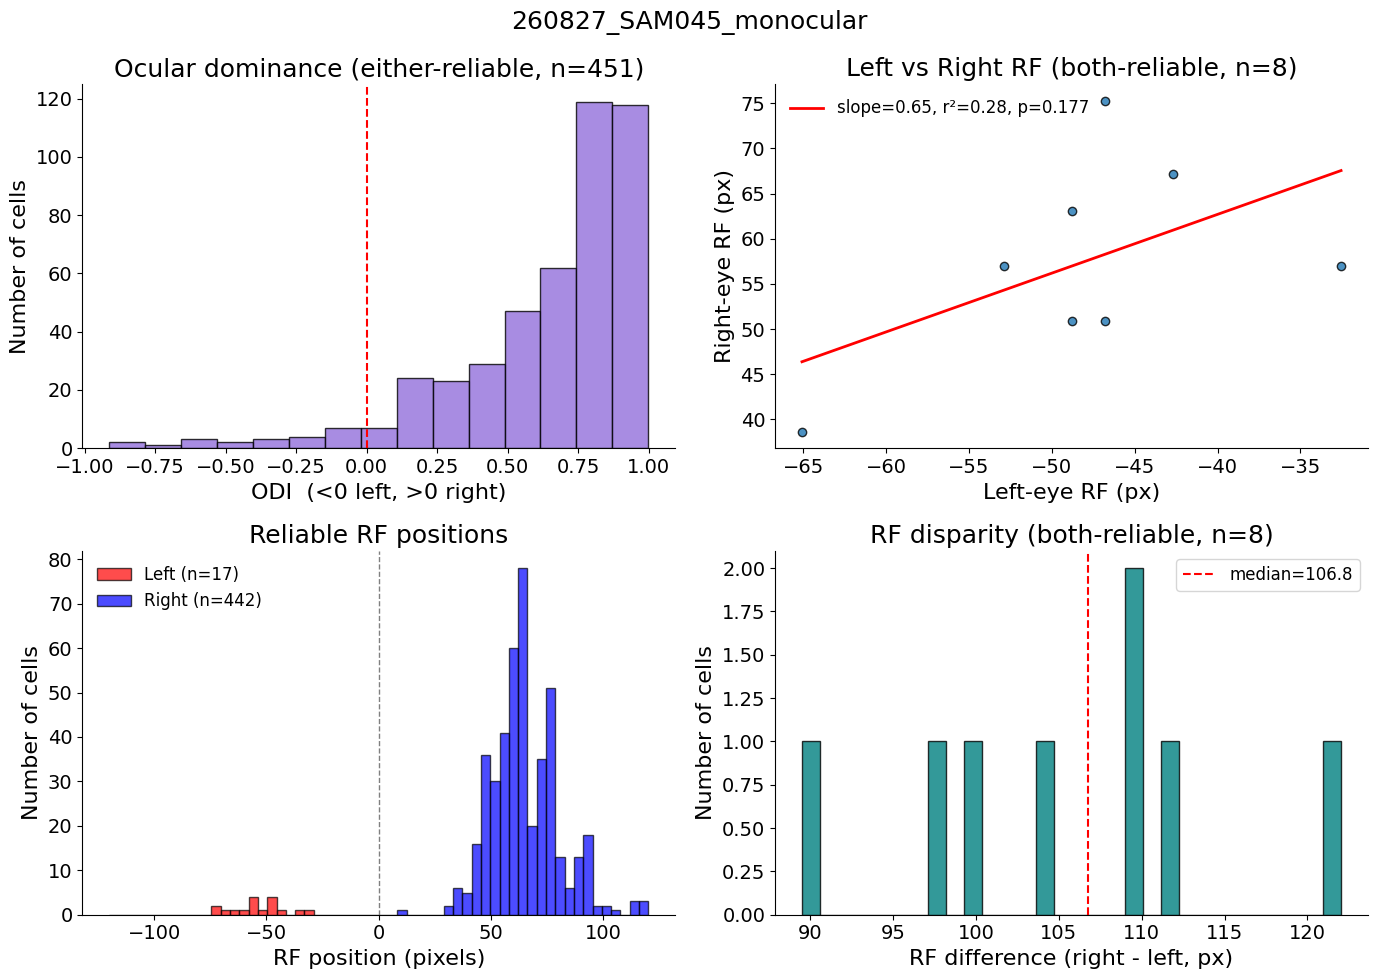

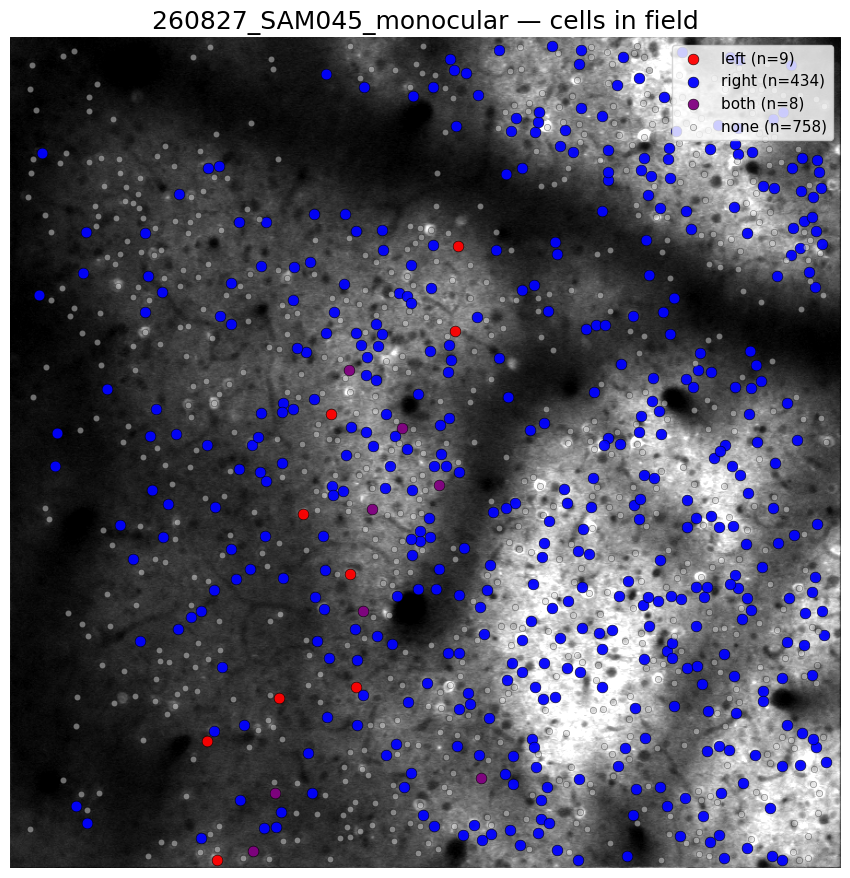

In [20]:
from src.viz.SessionVisualizer import SessionVisualizer

sv = SessionVisualizer(M, stats_df=stats_df, corr_threshold=0.7)
sv.print_summary()
sv.plot_summary()          # ODI histogram, left-vs-right RF scatter, RF overlay, RF disparity
sv.plot_location_map()     # cells on the FOV, colored by which eye reliably drives them

10 left-reliable cells (120px): [62, 77, 266, 273, 405, 510, 511, 609, 697, 727]


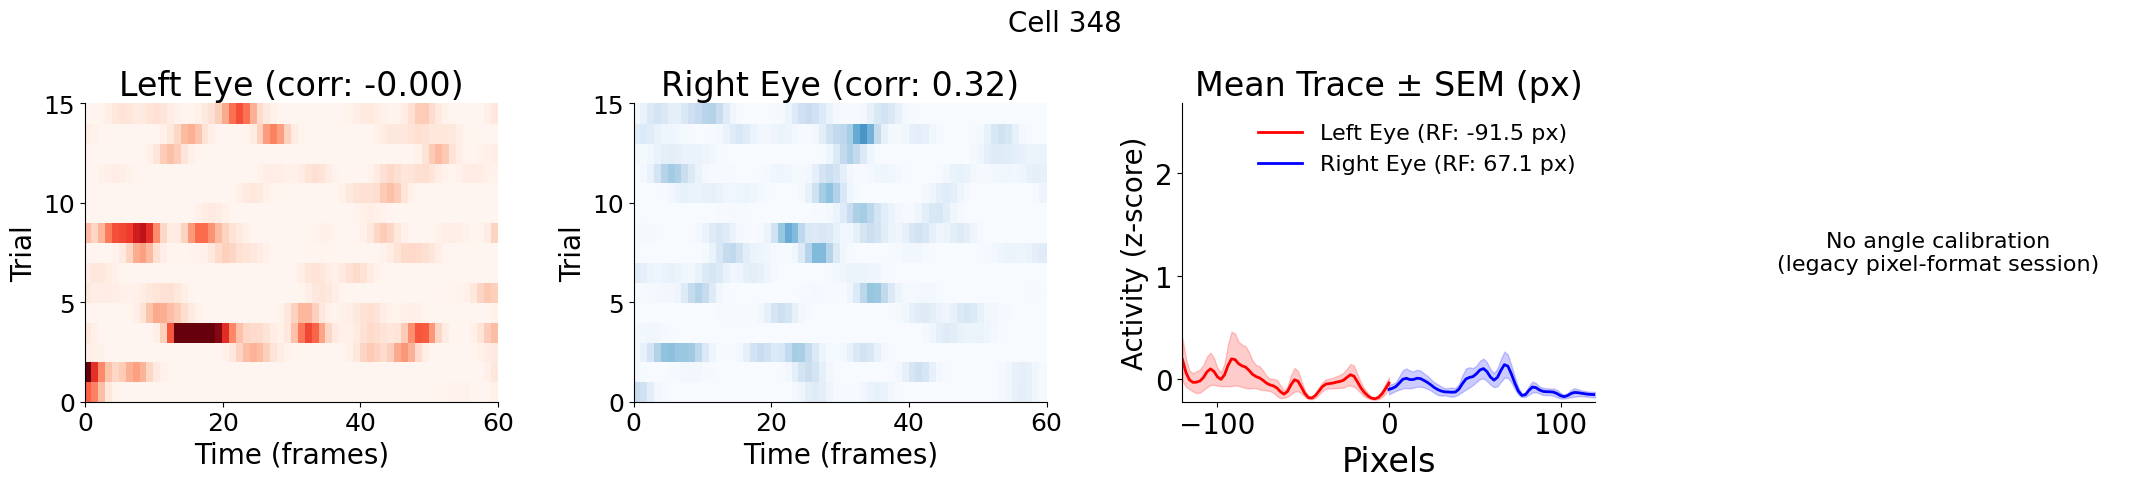

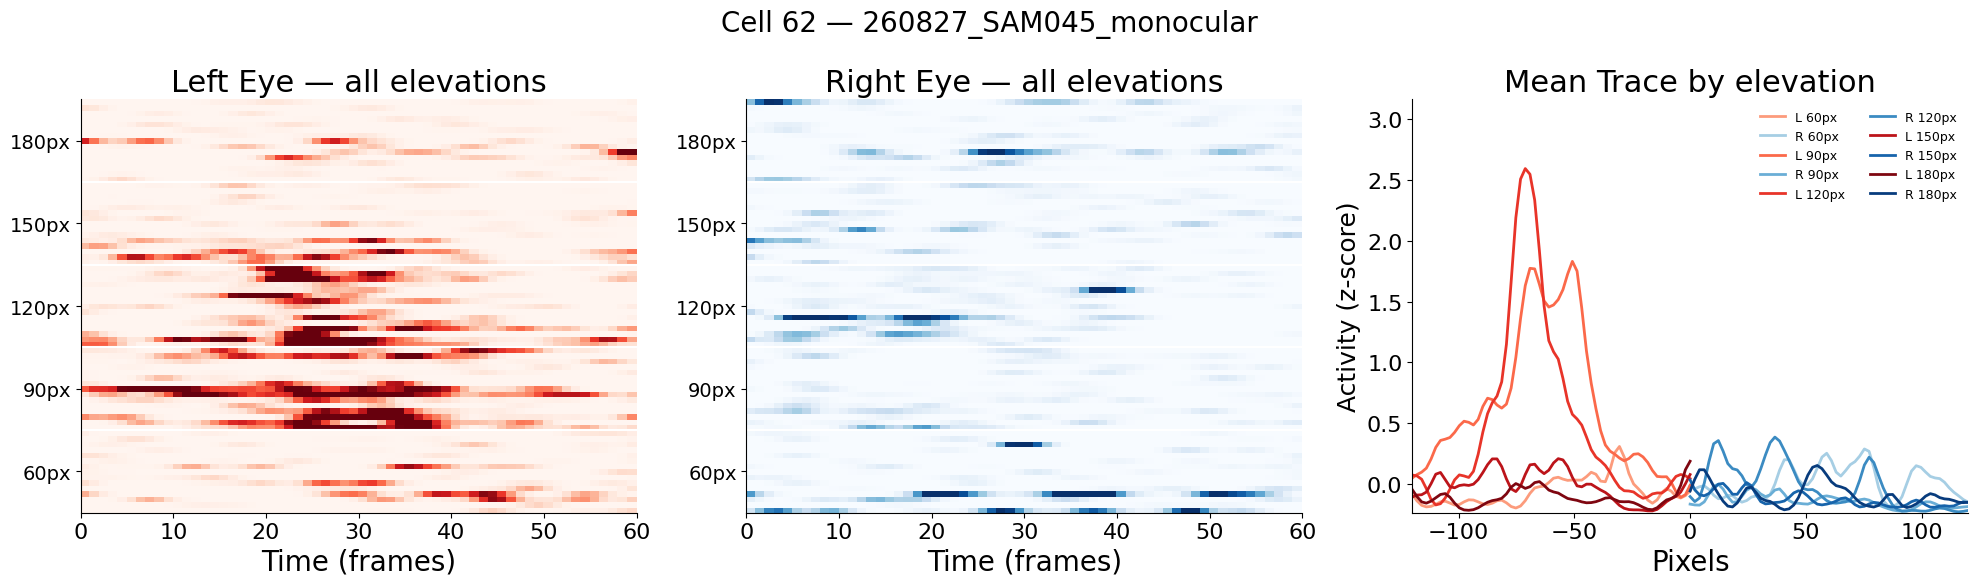

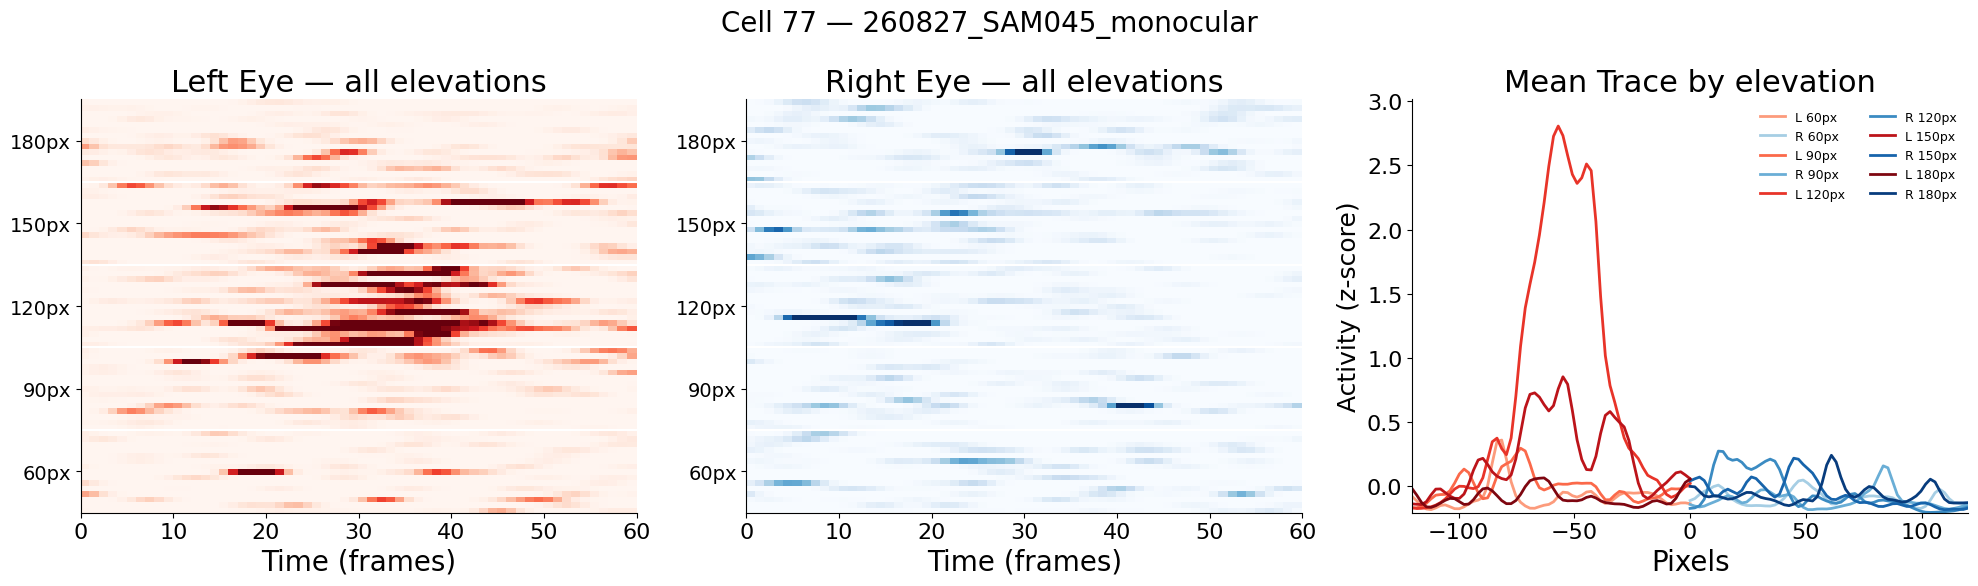

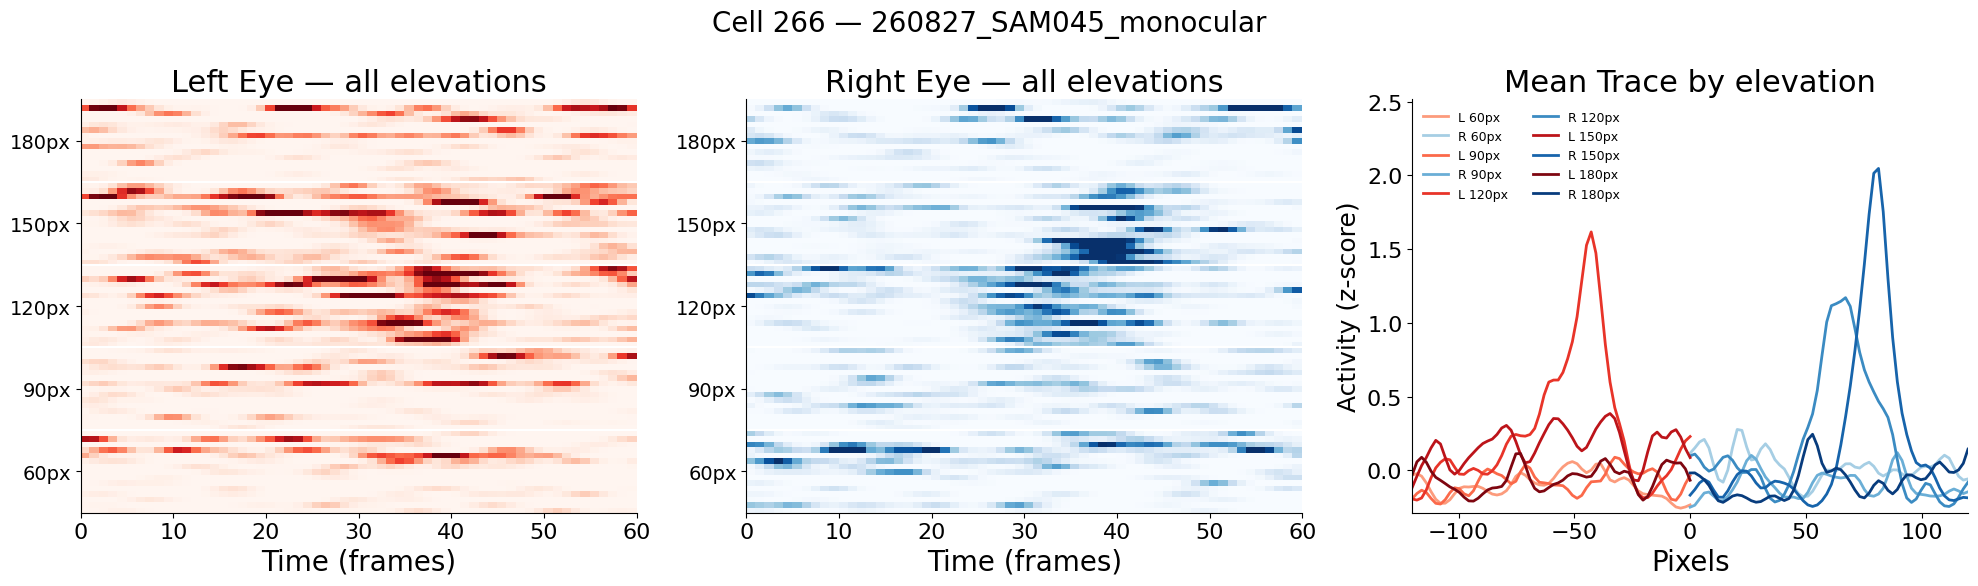

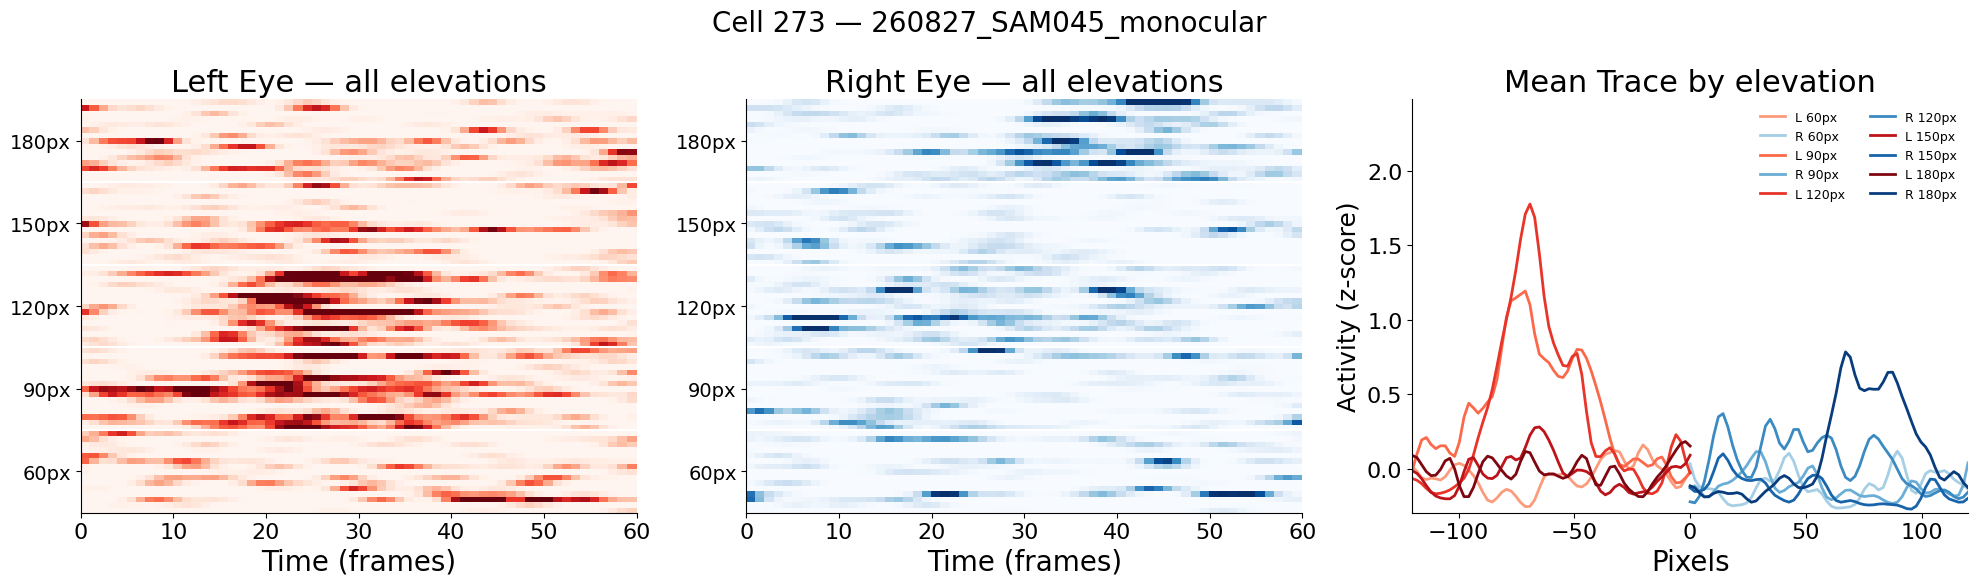

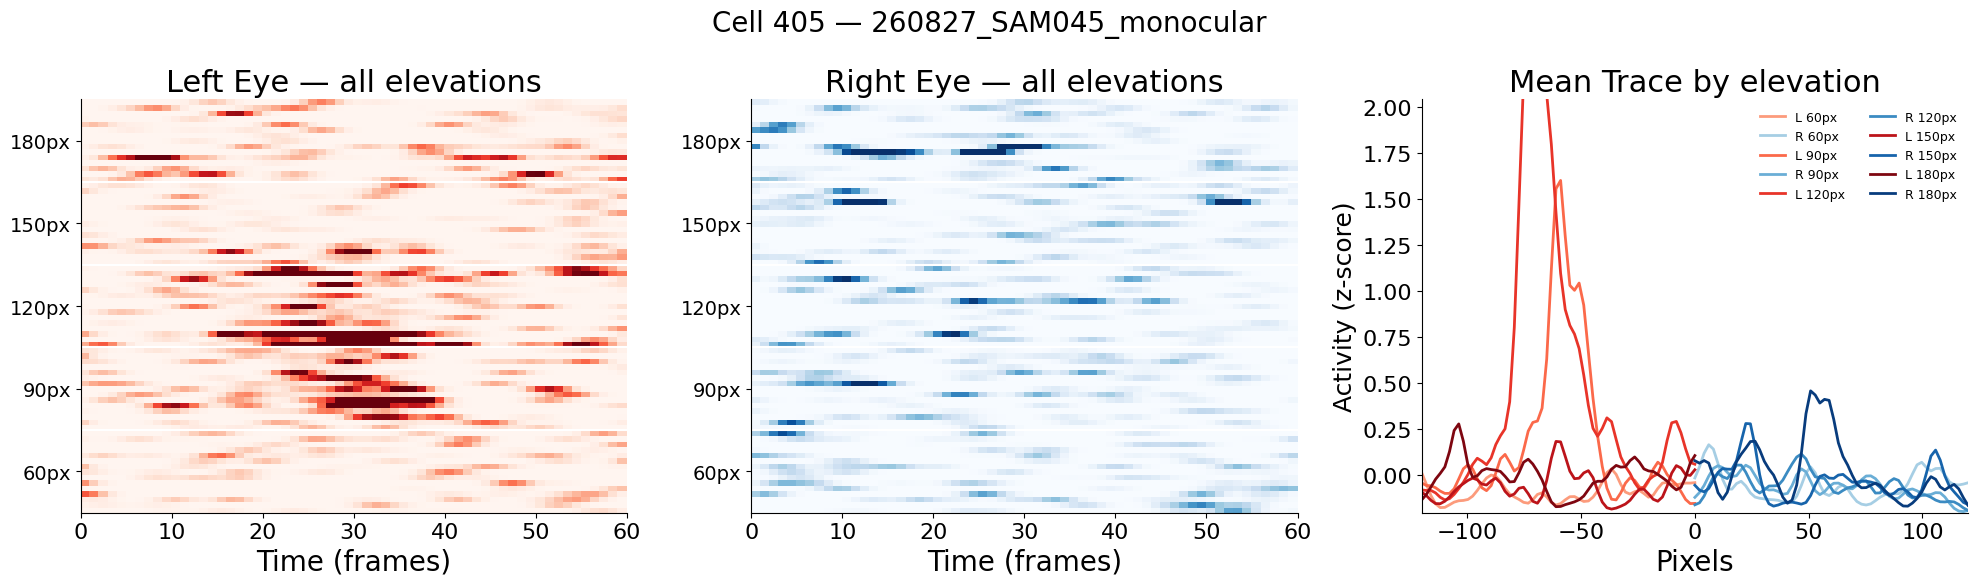

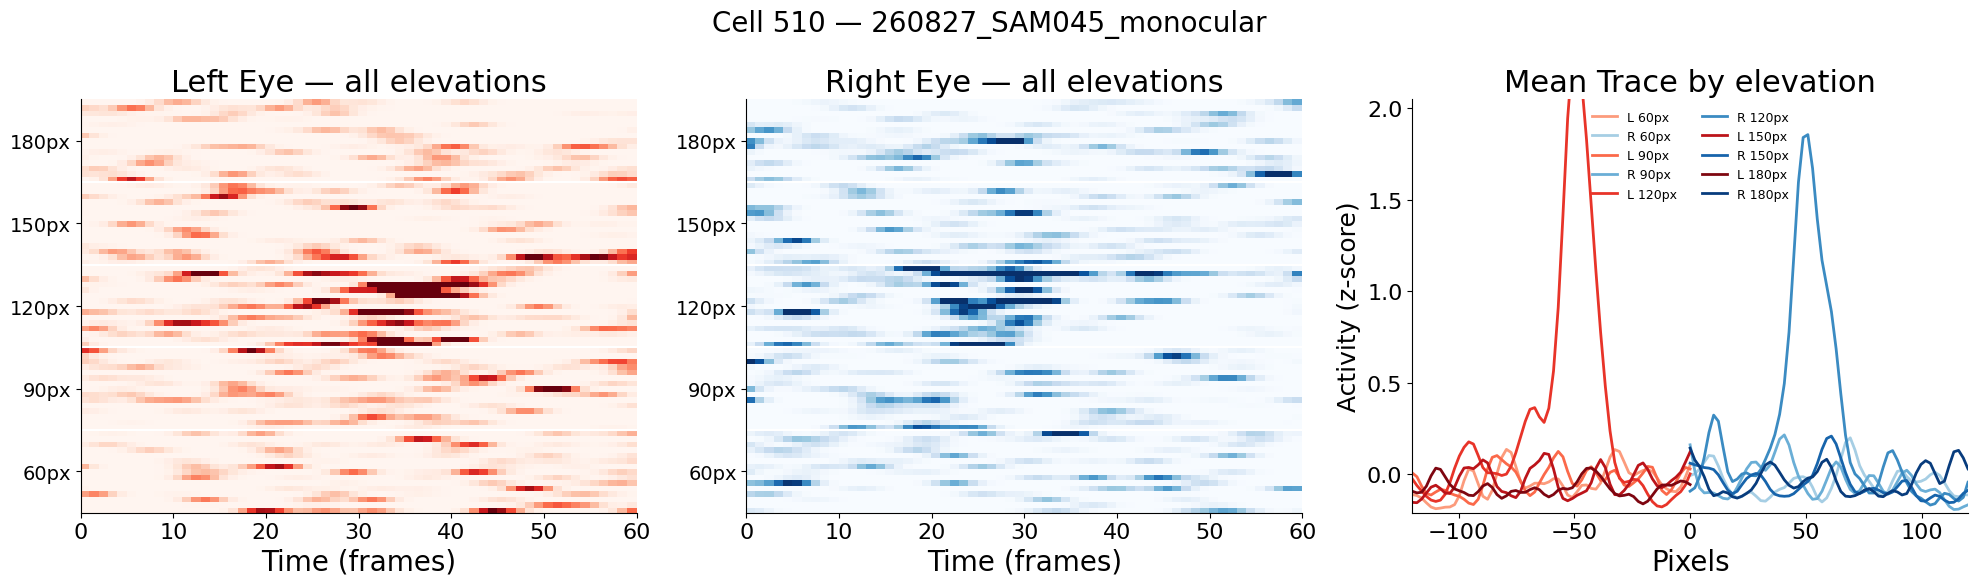

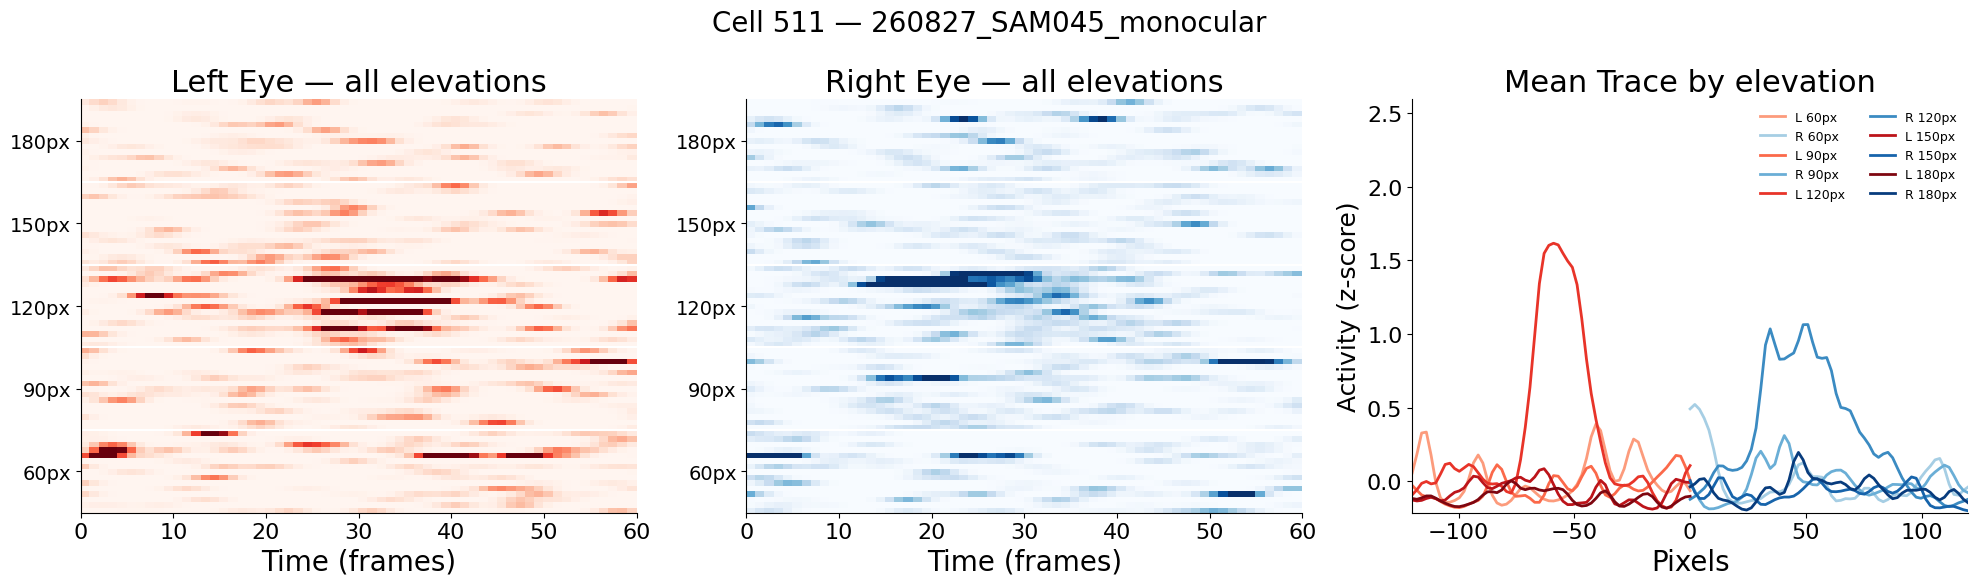

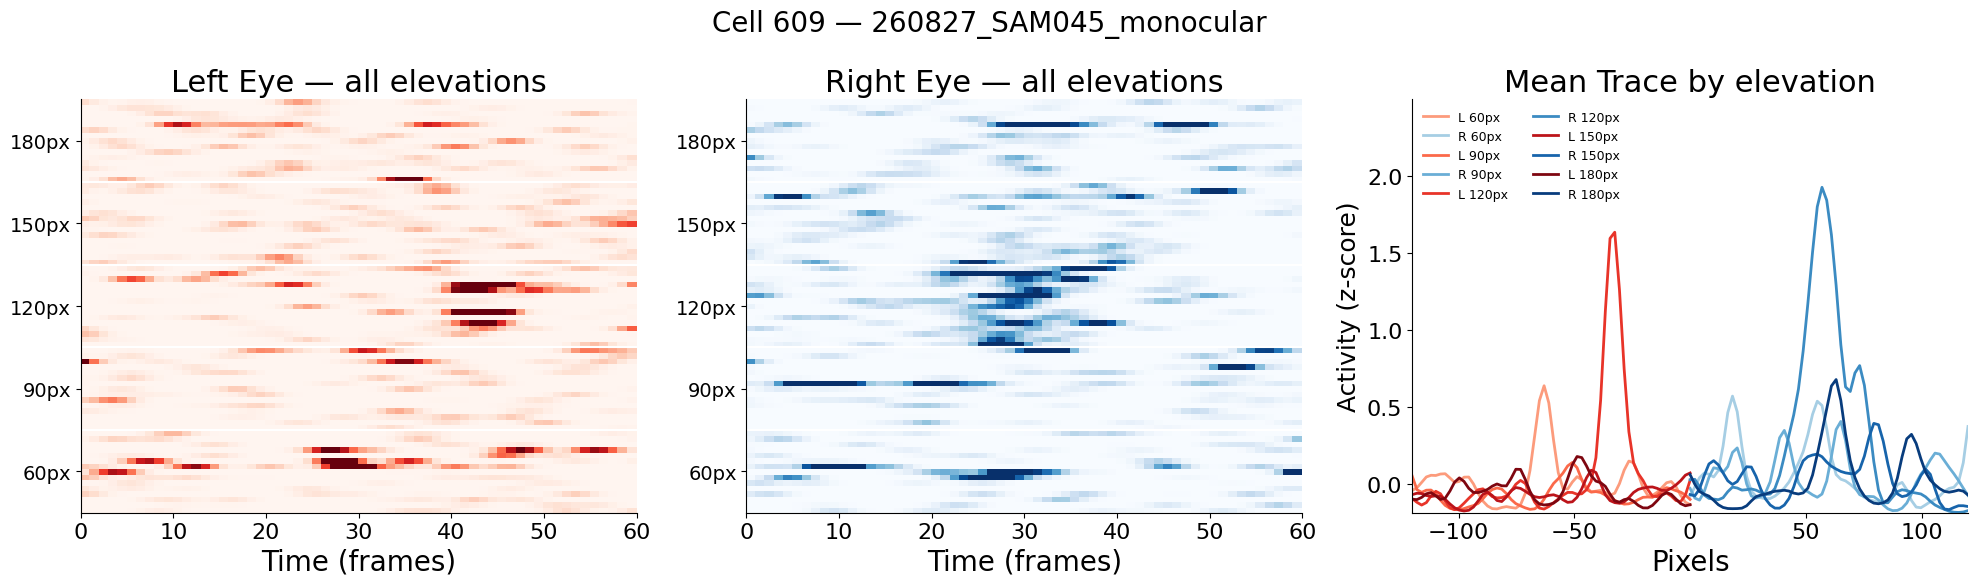

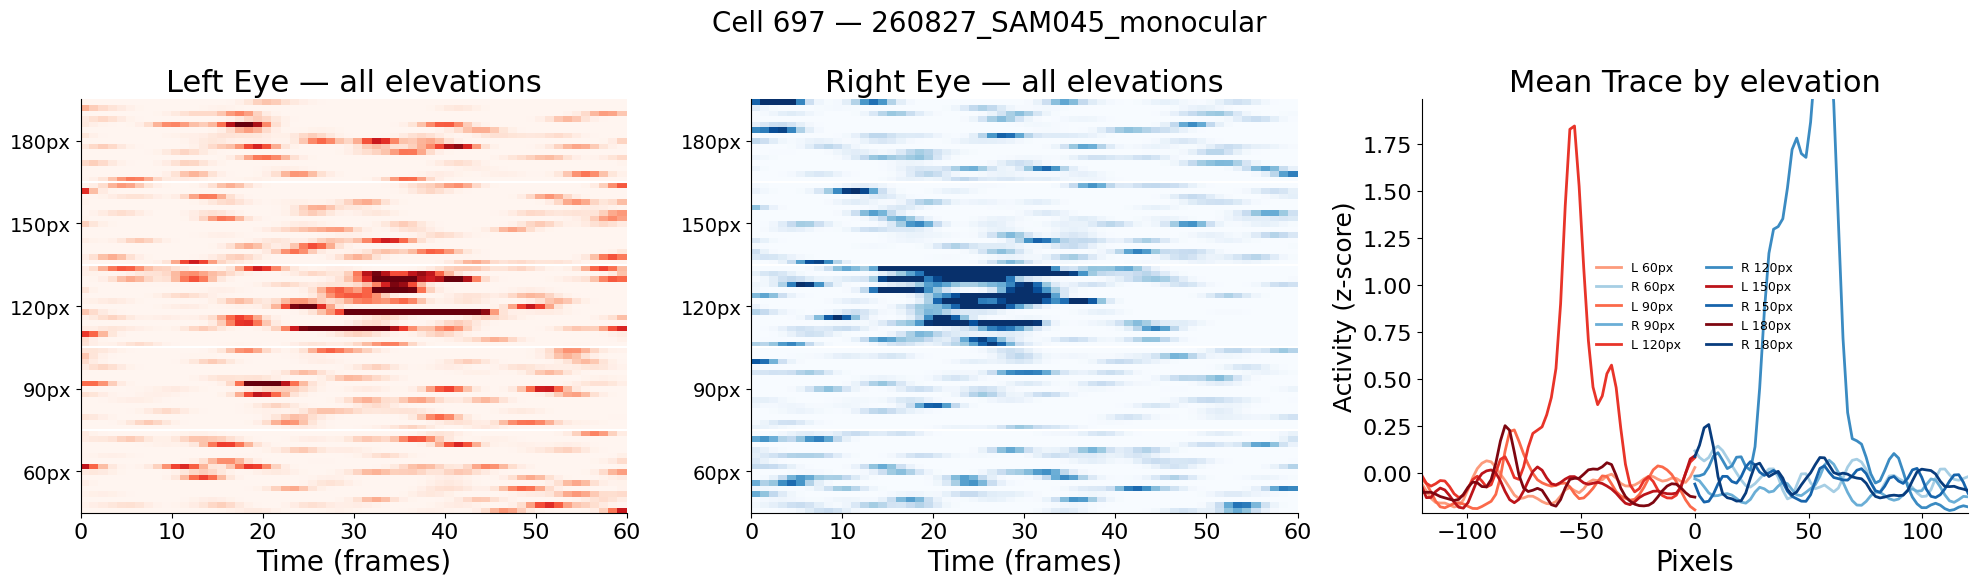

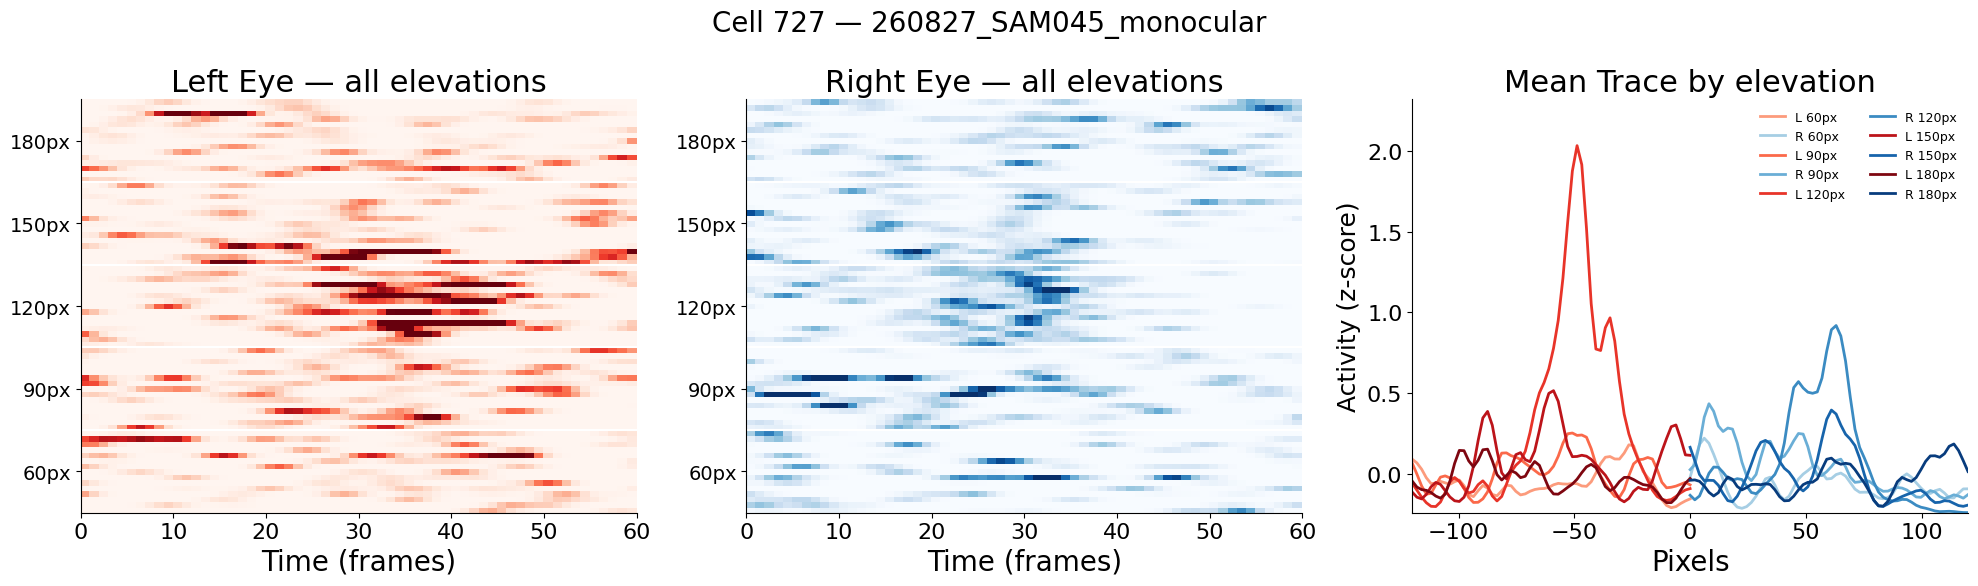

In [19]:
from src.viz.CellVisualizer import CellVisualizer

cv = CellVisualizer(M, stats_df=stats_df, elevation=120.0)
cv.make_comparison_plot(cell=348)   # pick any suite2p_id from M.suite2p_id

sets = sv.reliable_sets()
left_cells = sorted(sets['left'])
print(f"{len(left_cells)} left-reliable cells (120px): {left_cells}")

for cell in left_cells:
    cv.make_elevation_comparison_plot(cell)